In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the loan data
df = pd.read_csv('Task 3 and 4_Loan_Data.csv')

# Quick look
print("Shape:", df.shape)
df.head()

Shape: (10000, 8)


,customer_id,credit_lines_outstanding,loan_amt_outstanding,total_debt_outstanding,income,years_employed,fico_score,default
0,8153374,0,5221.545193,3915.471226,78039.38546,5,605,0
1,7442532,5,1958.928726,8228.752520,26648.43525,2,572,1
2,2256073,0,3363.009259,2027.830850,65866.71246,4,602,0
3,4885975,0,4766.648001,2501.730397,74356.88347,5,612,0
4,4700614,1,1345.827718,1768.826187,23448.32631,6,631,0


In [2]:
# 1. Data types
print("Dtypes:")
print(df[['fico_score', 'default']].dtypes)
print()

# 2. Missing values
print("Missing values:")
print(df[['fico_score', 'default']].isnull().sum())
print()

# 3. FICO range
print("FICO range:", df['fico_score'].min(), "to", df['fico_score'].max())
print()

# 4. Default distribution
print("Default counts:")
print(df['default'].value_counts())
print()
print("Default rate:", df['default'].mean().round(4))

Dtypes:
fico_score    int64
default       int64
dtype: object

Missing values:
fico_score    0
default       0
dtype: int64

FICO range: 408 to 850

Default counts:
default
0    8149
1    1851
Name: count, dtype: int64

Default rate: 0.1851


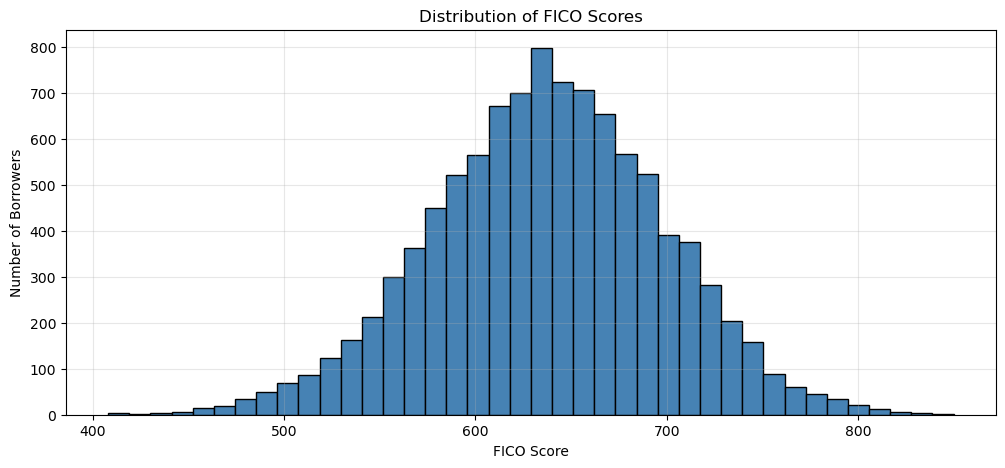

In [3]:
plt.figure(figsize=(12, 5))
plt.hist(df['fico_score'], bins=40, color='steelblue', edgecolor='black')
plt.xlabel('FICO Score')
plt.ylabel('Number of Borrowers')
plt.title('Distribution of FICO Scores')
plt.grid(True, alpha=0.3)
plt.show()

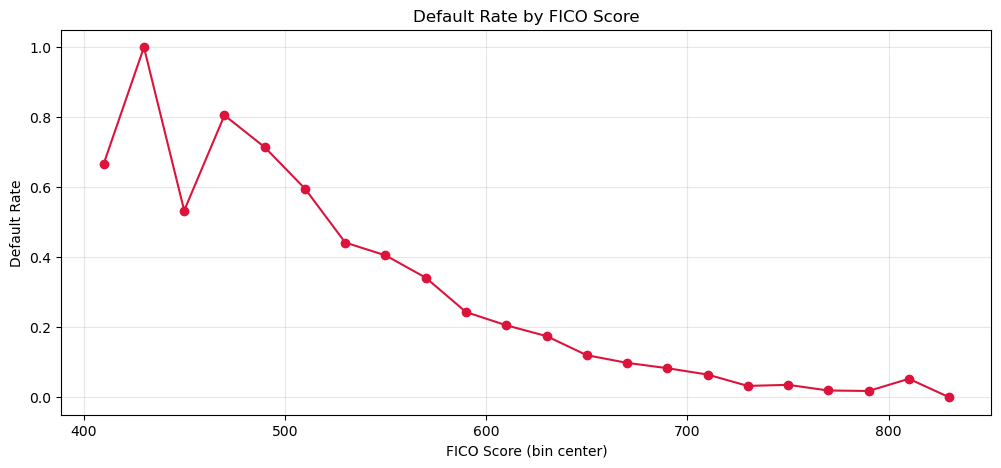

                mean  count
fico_bin                   
(400, 420]  0.666667      3
(420, 440]  1.000000      3
(440, 460]  0.533333     15
(460, 480]  0.805556     36
(480, 500]  0.714286     98
(500, 520]  0.595890    146
(520, 540]  0.441948    267
(540, 560]  0.405345    449
(560, 580]  0.341534    691
(580, 600]  0.243326    974
(600, 620]  0.205527   1158
(620, 640]  0.174579   1306
(640, 660]  0.120062   1291
(660, 680]  0.098175   1151
(680, 700]  0.082974    928
(700, 720]  0.064759    664
(720, 740]  0.032258    403
(740, 760]  0.035398    226
(760, 780]  0.019231    104
(780, 800]  0.017857     56
(800, 820]  0.052632     19
(820, 840]  0.000000     11


In [4]:
# Group FICO into bins of width 20, compute default rate in each bin
df['fico_bin'] = pd.cut(df['fico_score'], bins=range(400, 860, 20))
default_by_bin = df.groupby('fico_bin', observed=True)['default'].agg(['mean', 'count'])

# Use the center of each bin as the x-value
bin_centers = [interval.left + 10 for interval in default_by_bin.index]

plt.figure(figsize=(12, 5))
plt.plot(bin_centers, default_by_bin['mean'], marker='o', color='crimson')
plt.xlabel('FICO Score (bin center)')
plt.ylabel('Default Rate')
plt.title('Default Rate by FICO Score')
plt.grid(True, alpha=0.3)
plt.show()

# Print the underlying numbers
print(default_by_bin)

In [5]:
df['fico_bin'] = pd.cut(df['fico_score'], bins=range(400, 860, 20))

In [6]:
# Get unique FICO values and their counts, sorted
fico_series = df['fico_score'].sort_values().values  # sorted array of all 10000 FICO scores
unique_vals, counts = np.unique(fico_series, return_counts=True)
m = len(unique_vals)

print("Number of unique FICO values:", m)
print("First 5 unique values:", unique_vals[:5])
print("First 5 counts:      ", counts[:5])

# Precompute cumulative sums for O(1) bucket cost
# cum_n[i]  = total number of borrowers in unique_vals[0..i-1]
# cum_x[i]  = sum of FICO scores (weighted by count) in unique_vals[0..i-1]
# cum_x2[i] = sum of FICO scores squared in unique_vals[0..i-1]
cum_n  = np.concatenate([[0], np.cumsum(counts)])
cum_x  = np.concatenate([[0], np.cumsum(unique_vals * counts)])
cum_x2 = np.concatenate([[0], np.cumsum(unique_vals**2 * counts)])

def bucket_sse(a, b):
    """
    Sum of squared errors for a bucket containing unique_vals[a..b-1].
    Uses the identity: SSE = sum(x^2) - n * mean^2
    """
    n  = cum_n[b]  - cum_n[a]
    if n == 0:
        return 0.0
    sx = cum_x[b]  - cum_x[a]
    sx2 = cum_x2[b] - cum_x2[a]
    mean = sx / n
    return sx2 - n * mean**2

# Sanity check: SSE of the whole range should equal 10000 * variance of FICO
whole_sse = bucket_sse(0, m)
print("Whole-range SSE:", round(whole_sse, 2))
print("For comparison, n * var:", round(len(fico_series) * fico_series.var(), 2))

Number of unique FICO values: 374
First 5 unique values: [408 409 418 425 438]
First 5 counts:       [1 1 1 1 1]
Whole-range SSE: 36790136.71
For comparison, n * var: 36790136.71


In [7]:
K = 5  # number of buckets

# Initialize DP tables
# dp[i][k] = min SSE for splitting first i unique values into k buckets
# We use np.inf as the "impossible / not yet computed" sentinel
dp = np.full((m + 1, K + 1), np.inf)
split = np.zeros((m + 1, K + 1), dtype=int)

# Base case: 1 bucket
for i in range(1, m + 1):
    dp[i][1] = bucket_sse(0, i)

# Fill in the table for k = 2, 3, ..., K
for k in range(2, K + 1):
    for i in range(k, m + 1):
        # Try every possible position for the last boundary
        for t in range(k - 1, i):
            cost = dp[t][k - 1] + bucket_sse(t, i)
            if cost < dp[i][k]:
                dp[i][k] = cost
                split[i][k] = t

# The minimum total SSE for splitting all m unique values into K buckets
total_sse = dp[m][K]
print(f"Total SSE with {K} buckets:", round(total_sse, 2))
print(f"Reduction from 1-bucket baseline: {(1 - total_sse/dp[m][1])*100:.1f}%")

# Reconstruct the boundaries by walking backwards through split
boundaries_idx = []
i, k = m, K
while k > 1:
    t = split[i][k]
    boundaries_idx.append(t)
    i, k = t, k - 1
boundaries_idx.reverse()

# Convert indices in unique_vals back to actual FICO scores
# split index t means "the first t values go into buckets 1..k-1, and
# values from position t onwards are in the next bucket"
# So the boundary is between unique_vals[t-1] and unique_vals[t]
boundaries_fico = [unique_vals[t] for t in boundaries_idx]

print("\nMSE-optimal boundaries (FICO cutoffs):", boundaries_fico)

# Build the actual bucket ranges for readability
bucket_edges = [unique_vals[0]] + boundaries_fico + [unique_vals[-1] + 1]
print("\nBucket ranges:")
for j in range(K):
    lo, hi = bucket_edges[j], bucket_edges[j+1]
    # count borrowers in this range
    mask = (df['fico_score'] >= lo) & (df['fico_score'] < hi)
    n_in = mask.sum()
    n_def = df.loc[mask, 'default'].sum()
    mean_fico = df.loc[mask, 'fico_score'].mean()
    print(f"  Bucket {j+1}: FICO [{lo}, {hi})  |  n={n_in:5d}  mean={mean_fico:6.1f}  defaults={n_def:4d} ({n_def/n_in*100:.1f}%)")

Total SSE with 5 buckets: 2976841.85
Reduction from 1-bucket baseline: 91.9%

MSE-optimal boundaries (FICO cutoffs): [np.int64(553), np.int64(608), np.int64(655), np.int64(707)]

Bucket ranges:
  Bucket 1: FICO [408, 553)  |  n=  797  mean= 522.1  defaults= 428 (53.7%)
  Bucket 2: FICO [553, 608)  |  n= 2240  mean= 583.4  defaults= 635 (28.3%)
  Bucket 3: FICO [608, 655)  |  n= 3036  mean= 631.5  defaults= 488 (16.1%)
  Bucket 4: FICO [655, 707)  |  n= 2634  mean= 677.8  defaults= 242 (9.2%)
  Bucket 5: FICO [707, 851)  |  n= 1293  mean= 734.9  defaults=  58 (4.5%)


In [8]:
# For each unique FICO value, count total borrowers AND total defaults
# We already have unique_vals and counts (from earlier)
# Now compute defaults per unique value

# Group by fico_score and sum defaults
defaults_per_fico = df.groupby('fico_score')['default'].sum()

# defaults_per_fico is a Series indexed by fico_score.
# We need to align it with unique_vals (which is sorted).
default_counts = defaults_per_fico.loc[unique_vals].values

print("Sanity check — first 5 unique FICO values:")
for i in range(5):
    print(f"  FICO {unique_vals[i]}: {counts[i]} borrowers, {default_counts[i]} defaults")

print(f"\nTotal defaults across all unique values: {default_counts.sum()}")
print(f"Should match df['default'].sum(): {df['default'].sum()}")

# Cumulative sum of defaults (with leading 0, matching cum_n structure)
cum_k = np.concatenate([[0], np.cumsum(default_counts)])

# Bucket log-likelihood cost function
def bucket_neg_ll(a, b):
    """
    Negative log-likelihood contribution for a bucket containing unique_vals[a..b-1].
    """
    n = cum_n[b] - cum_n[a]
    k = cum_k[b] - cum_k[a]
    if n == 0:
        return 0.0
    # Edge cases: p=0 or p=1 give zero contribution (perfect prediction)
    if k == 0 or k == n:
        return 0.0
    p = k / n
    ll = k * np.log(p) + (n - k) * np.log(1 - p)
    return -ll

# Sanity check: neg-log-likelihood of the whole range (1 bucket)
whole_neg_ll = bucket_neg_ll(0, m)
print(f"\nWhole-range negative log-likelihood (1 bucket): {whole_neg_ll:.2f}")

Sanity check — first 5 unique FICO values:
  FICO 408: 1 borrowers, 0 defaults
  FICO 409: 1 borrowers, 1 defaults
  FICO 418: 1 borrowers, 1 defaults
  FICO 425: 1 borrowers, 1 defaults
  FICO 438: 1 borrowers, 1 defaults

Total defaults across all unique values: 1851
Should match df['default'].sum(): 1851

Whole-range negative log-likelihood (1 bucket): 4790.39


In [9]:
K = 5  # same number of buckets as before

# Initialize DP tables for log-likelihood
dp_ll = np.full((m + 1, K + 1), np.inf)
split_ll = np.zeros((m + 1, K + 1), dtype=int)

# Base case: 1 bucket
for i in range(1, m + 1):
    dp_ll[i][1] = bucket_neg_ll(0, i)

# Fill in the table for k = 2, 3, ..., K
for k in range(2, K + 1):
    for i in range(k, m + 1):
        for t in range(k - 1, i):
            cost = dp_ll[t][k - 1] + bucket_neg_ll(t, i)
            if cost < dp_ll[i][k]:
                dp_ll[i][k] = cost
                split_ll[i][k] = t

total_neg_ll = dp_ll[m][K]
print(f"Total negative log-likelihood with {K} buckets: {total_neg_ll:.2f}")
print(f"Reduction from 1-bucket baseline: {(1 - total_neg_ll/dp_ll[m][1])*100:.1f}%")

# Reconstruct the boundaries
boundaries_idx_ll = []
i, k = m, K
while k > 1:
    t = split_ll[i][k]
    boundaries_idx_ll.append(t)
    i, k = t, k - 1
boundaries_idx_ll.reverse()

boundaries_fico_ll = [int(unique_vals[t]) for t in boundaries_idx_ll]
print(f"\nLog-likelihood-optimal boundaries (FICO cutoffs): {boundaries_fico_ll}")

# Print the buckets
bucket_edges_ll = [unique_vals[0]] + boundaries_fico_ll + [unique_vals[-1] + 1]
print("\nBucket ranges:")
for j in range(K):
    lo, hi = bucket_edges_ll[j], bucket_edges_ll[j+1]
    mask = (df['fico_score'] >= lo) & (df['fico_score'] < hi)
    n_in = mask.sum()
    n_def = df.loc[mask, 'default'].sum()
    mean_fico = df.loc[mask, 'fico_score'].mean()
    print(f"  Bucket {j+1}: FICO [{lo}, {hi})  |  n={n_in:5d}  mean={mean_fico:6.1f}  defaults={n_def:4d} ({n_def/n_in*100:.1f}%)")

Total negative log-likelihood with 5 buckets: 4255.38
Reduction from 1-bucket baseline: 11.2%

Log-likelihood-optimal boundaries (FICO cutoffs): [521, 581, 641, 697]

Bucket ranges:
  Bucket 1: FICO [408, 521)  |  n=  301  mean= 495.2  defaults= 199 (66.1%)
  Bucket 2: FICO [521, 581)  |  n= 1407  mean= 557.2  defaults= 536 (38.1%)
  Bucket 3: FICO [581, 641)  |  n= 3438  mean= 612.8  defaults= 703 (20.4%)
  Bucket 4: FICO [641, 697)  |  n= 3197  mean= 666.4  defaults= 336 (10.5%)
  Bucket 5: FICO [697, 851)  |  n= 1657  mean= 727.5  defaults=  77 (4.6%)


In [10]:
def fit_buckets_mse(fico_scores, K):
    """
    Find K buckets minimizing total MSE (ignores defaults).
    Returns list of boundary FICO values (length K-1).
    """
    scores_sorted = np.sort(np.asarray(fico_scores))
    unique_vals, counts = np.unique(scores_sorted, return_counts=True)
    m = len(unique_vals)

    cum_n  = np.concatenate([[0], np.cumsum(counts)])
    cum_x  = np.concatenate([[0], np.cumsum(unique_vals * counts)])
    cum_x2 = np.concatenate([[0], np.cumsum(unique_vals**2 * counts)])

    def sse(a, b):
        n = cum_n[b] - cum_n[a]
        if n == 0: return 0.0
        sx  = cum_x[b]  - cum_x[a]
        sx2 = cum_x2[b] - cum_x2[a]
        return sx2 - (sx * sx) / n  # equivalent to sx2 - n*mean^2

    dp = np.full((m + 1, K + 1), np.inf)
    split = np.zeros((m + 1, K + 1), dtype=int)
    for i in range(1, m + 1):
        dp[i][1] = sse(0, i)
    for k in range(2, K + 1):
        for i in range(k, m + 1):
            for t in range(k - 1, i):
                cost = dp[t][k - 1] + sse(t, i)
                if cost < dp[i][k]:
                    dp[i][k] = cost
                    split[i][k] = t

    boundaries = []
    i, k = m, K
    while k > 1:
        t = split[i][k]
        boundaries.append(int(unique_vals[t]))
        i, k = t, k - 1
    boundaries.reverse()
    return boundaries


def fit_buckets_ll(fico_scores, defaults, K):
    """
    Find K buckets maximizing log-likelihood of defaults.
    Returns list of boundary FICO values (length K-1).
    """
    fico = np.asarray(fico_scores)
    defs = np.asarray(defaults)
    order = np.argsort(fico)
    fico = fico[order]
    defs = defs[order]

    unique_vals, first_idx, counts = np.unique(fico, return_index=True, return_counts=True)
    m = len(unique_vals)

    # Sum defaults per unique FICO value
    default_counts = np.zeros(m, dtype=int)
    for i in range(m):
        start = first_idx[i]
        default_counts[i] = defs[start:start + counts[i]].sum()

    cum_n = np.concatenate([[0], np.cumsum(counts)])
    cum_k = np.concatenate([[0], np.cumsum(default_counts)])

    def neg_ll(a, b):
        n = cum_n[b] - cum_n[a]
        k = cum_k[b] - cum_k[a]
        if n == 0 or k == 0 or k == n:
            return 0.0
        p = k / n
        return -(k * np.log(p) + (n - k) * np.log(1 - p))

    dp = np.full((m + 1, K + 1), np.inf)
    split = np.zeros((m + 1, K + 1), dtype=int)
    for i in range(1, m + 1):
        dp[i][1] = neg_ll(0, i)
    for k in range(2, K + 1):
        for i in range(k, m + 1):
            for t in range(k - 1, i):
                cost = dp[t][k - 1] + neg_ll(t, i)
                if cost < dp[i][k]:
                    dp[i][k] = cost
                    split[i][k] = t

    boundaries = []
    i, k = m, K
    while k > 1:
        t = split[i][k]
        boundaries.append(int(unique_vals[t]))
        i, k = t, k - 1
    boundaries.reverse()
    return boundaries


def fico_to_rating(fico, boundaries):
    """
    Map FICO score(s) to a rating from 1 (best credit) to K (worst credit).
    Convention: lower rating = better credit = higher FICO.

    boundaries is the list of K-1 cutoffs (ascending) returned by fit_buckets_*.
    """
    fico_arr = np.atleast_1d(np.asarray(fico))
    K = len(boundaries) + 1
    # np.searchsorted with the ascending boundaries gives us bucket index 0..K-1
    # where 0 = lowest FICO group.
    bucket_from_bottom = np.searchsorted(boundaries, fico_arr, side='right')
    # Flip so that best FICO (highest) gets rating 1
    rating = K - bucket_from_bottom
    # Return scalar if input was scalar
    return int(rating[0]) if np.isscalar(fico) or (hasattr(fico, 'ndim') and fico.ndim == 0) else rating

In [11]:
# Test 1: reproduce the earlier boundaries
fico_scores = df['fico_score'].values
defaults    = df['default'].values

mse_boundaries = fit_buckets_mse(fico_scores, K=5)
ll_boundaries  = fit_buckets_ll(fico_scores, defaults, K=5)

print("MSE boundaries:", mse_boundaries)
print("Expected:       [553, 608, 655, 707]")
print()
print("LL boundaries:  ", ll_boundaries)
print("Expected:       [521, 581, 641, 697]")
print()

# Test 2: rating mapping on scalar FICOs, using LL boundaries
print("Rating check (LL boundaries):")
test_ficos = [420, 500, 550, 600, 650, 700, 750, 800]
for f in test_ficos:
    r = fico_to_rating(f, ll_boundaries)
    print(f"  FICO {f} -> rating {r}")

# Test 3: rating on the whole dataset, and average default rate per rating
print("\nAverage default rate per rating (LL buckets):")
df['rating_ll'] = fico_to_rating(df['fico_score'].values, ll_boundaries)
print(df.groupby('rating_ll')['default'].agg(['mean', 'count']).round(3))

# Test 4: same for MSE
print("\nAverage default rate per rating (MSE buckets):")
df['rating_mse'] = fico_to_rating(df['fico_score'].values, mse_boundaries)
print(df.groupby('rating_mse')['default'].agg(['mean', 'count']).round(3))

# Test 5: edge cases
print("\nEdge case checks (LL boundaries):")
print(f"  FICO 408 (minimum): rating {fico_to_rating(408, ll_boundaries)}  (expect 5)")
print(f"  FICO 850 (maximum): rating {fico_to_rating(850, ll_boundaries)}  (expect 1)")
print(f"  FICO 521 (boundary): rating {fico_to_rating(521, ll_boundaries)}  (expect 4, side='right')")
print(f"  FICO 520 (just below): rating {fico_to_rating(520, ll_boundaries)}  (expect 5)")

MSE boundaries: [553, 608, 655, 707]
Expected:       [553, 608, 655, 707]

LL boundaries:   [521, 581, 641, 697]
Expected:       [521, 581, 641, 697]

Rating check (LL boundaries):
  FICO 420 -> rating 5
  FICO 500 -> rating 5
  FICO 550 -> rating 4
  FICO 600 -> rating 3
  FICO 650 -> rating 2
  FICO 700 -> rating 1
  FICO 750 -> rating 1
  FICO 800 -> rating 1

Average default rate per rating (LL buckets):
            mean  count
rating_ll              
1          0.046   1657
2          0.105   3197
3          0.204   3438
4          0.381   1407
5          0.661    301

Average default rate per rating (MSE buckets):
             mean  count
rating_mse              
1           0.045   1293
2           0.092   2634
3           0.161   3036
4           0.283   2240
5           0.537    797

Edge case checks (LL boundaries):
  FICO 408 (minimum): rating 5  (expect 5)
  FICO 850 (maximum): rating 1  (expect 1)
  FICO 521 (boundary): rating 4  (expect 4, side='right')
  FICO 520 (just b